In [5]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage.measure import label, regionprops
from skimage.morphology import disk, opening
from skimage.util import invert

# Load image
image = cv2.imread('barya.png')
if image is None:
    raise FileNotFoundError("Image not found.")

# Convert to RGB
image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

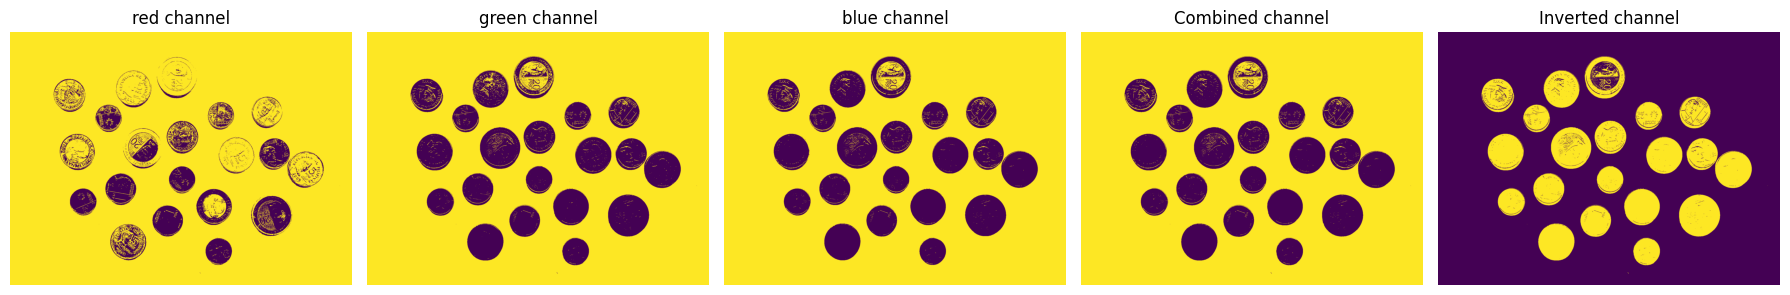

In [6]:
# Extract channels
rmat = image_rgb[:, :, 0]
gmat = image_rgb[:, :, 1]
bmat = image_rgb[:, :, 2]

# Threshold levels
levelr = 0.2 * 255
levelg = 0.4 * 255
levelb = 0.45 * 255

# Threshold RGB channels
Ired = (rmat > levelr).astype(np.uint8)
Igreen = (gmat > levelg).astype(np.uint8)
Iblue = (bmat > levelb).astype(np.uint8)

# Combine channels
It = cv2.bitwise_and(cv2.bitwise_and(Ired, Igreen), Iblue)

# Invert mask
Icomp = cv2.bitwise_not(It * 255)

#show image for each channel
fig, axs = plt.subplots(1, 5, figsize=(18, 12))
axs[0].imshow(Ired)
axs[0].set_title("red channel")
axs[0].axis("off")

axs[1].imshow(Igreen)
axs[1].set_title("green channel")
axs[1].axis("off")

axs[2].imshow(Iblue)
axs[2].set_title("blue channel")
axs[2].axis("off")

axs[3].imshow(It)
axs[3].set_title("Combined channel")
axs[3].axis("off")

axs[4].imshow(Icomp)
axs[4].set_title("Inverted channel")
axs[4].axis("off")

plt.tight_layout()
plt.show()

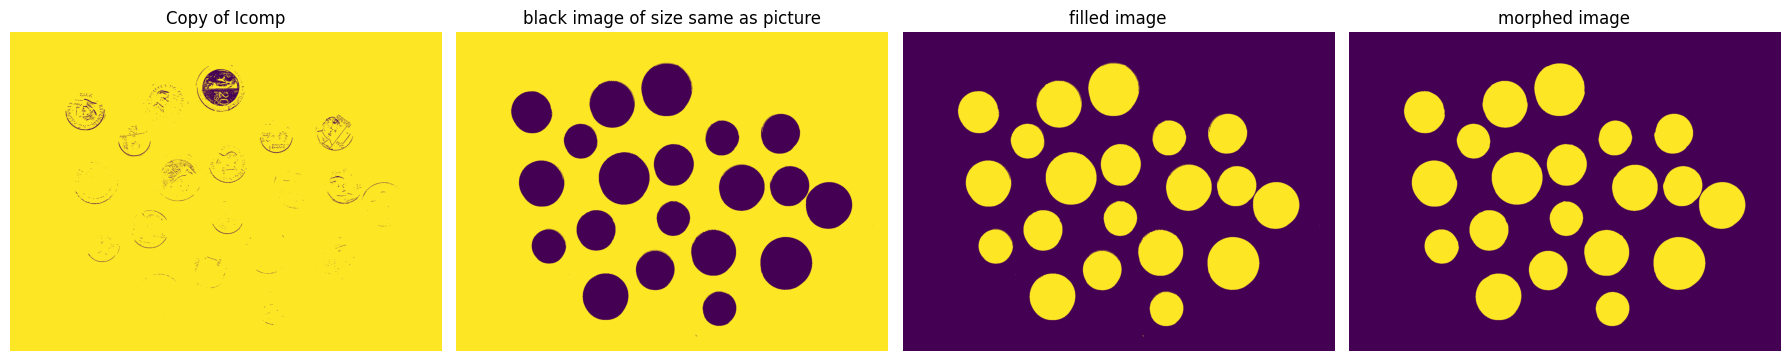

44944.0
35181.0
28564.0
25691.0
19503.0
19452.0
27929.0
44677.0
34814.0
35150.0
26123.0
36406.0
19193.0
26493.0
19454.0
34442.0
46167.0
25494.0
35840.0
19266.0


In [7]:
# Fill holes
flood_fill = Icomp.copy()
h, w = flood_fill.shape
mask = np.zeros((h+2, w+2), np.uint8)
cv2.floodFill(flood_fill, mask, (0, 0), 255)
filled = cv2.bitwise_or(Icomp, cv2.bitwise_not(flood_fill))

# Morphological open
opened = opening(filled // 255, disk(15)).astype(np.uint8)

# Label connected components
label_image = label(opened)
regions = regionprops(label_image)

#show image for each channel
fig, axs = plt.subplots(1, 4, figsize=(18, 12))
axs[0].imshow(flood_fill)
axs[0].set_title("Copy of Icomp")
axs[0].axis("off")

axs[1].imshow(mask)
axs[1].set_title("black image of size same as picture")
axs[1].axis("off")

axs[2].imshow(filled)
axs[2].set_title("filled image")
axs[2].axis("off")

axs[3].imshow(opened)
axs[3].set_title("morphed image")
axs[3].axis("off")


plt.tight_layout()
plt.show()
###
for region in regions:
        area = region.area
        print(area)

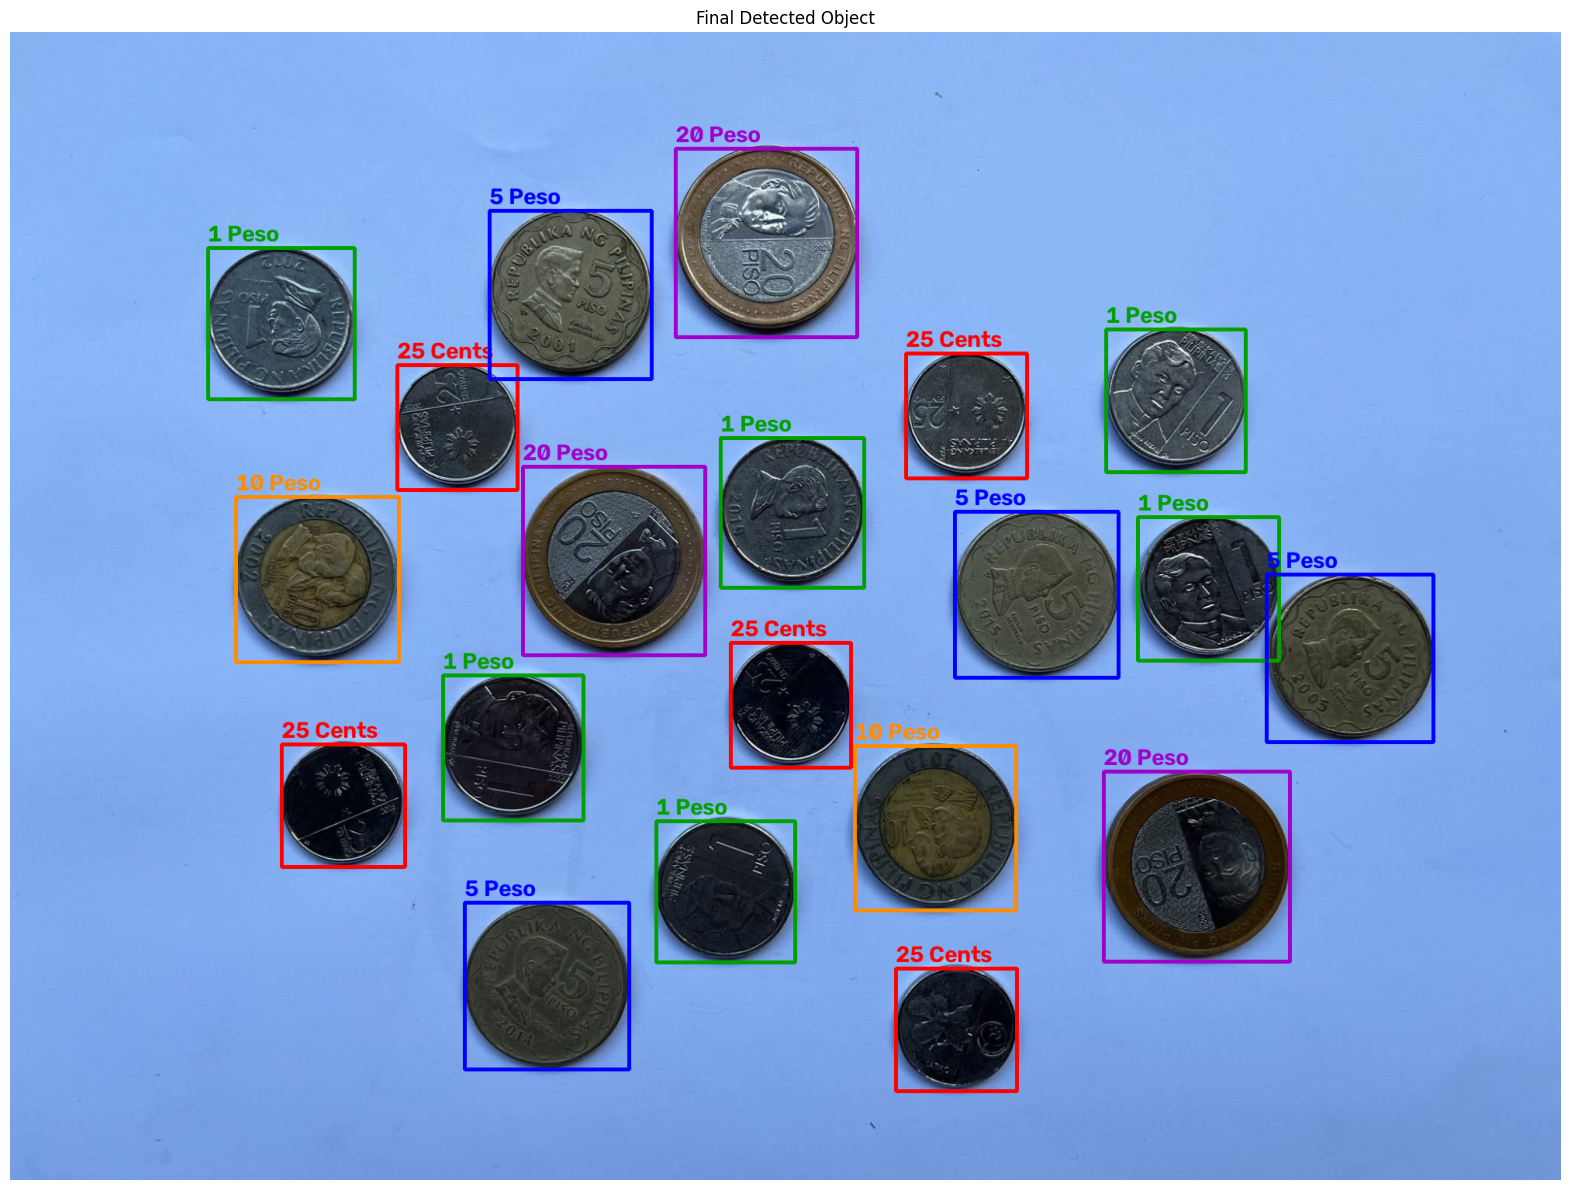

25 Cents: 5
1 Peso: 6
5 Peso: 4
10 Peso: 2
20 Peso: 3
count: 20
Total value: PHP 107.25


In [8]:
# Classify objects
cents, one, five, ten, twenty = [], [], [], [], []
for region in regions:
    area = region.area
    if area < 22000:
        cents.append(region)
    elif area < 31000:
        one.append(region)
    elif area < 35000:
        ten.append(region)
    elif area < 40500:
        five.append(region)
    else:
        twenty.append(region)

# Draw boxes on copy of image (each coin type has its own color)
output_img = image_rgb.copy()
COIN_STYLE = [
    (cents,  '25 Cents', (255, 0, 0)),
    (one,    '1 Peso',   (0, 160, 0)),
    (five,   '5 Peso',   (0, 0, 255)),
    (ten,    '10 Peso',  (255, 140, 0)),
    (twenty, '20 Peso',  (160, 0, 200)),
]
for group, name, color in COIN_STYLE:
    for region in group:
        minr, minc, maxr, maxc = region.bbox
        cv2.rectangle(output_img, (minc, minr), (maxc, maxr), color, 3)
        cv2.putText(output_img, name, (minc, max(minr - 8, 25)),
                    cv2.FONT_HERSHEY_SIMPLEX, 1, color, 2)

# Display results side-by-side
fig, axs = plt.subplots(1, 1, figsize=(18, 12))

axs.imshow(output_img)
axs.set_title("Final Detected Object")
axs.axis("off")

plt.tight_layout()
plt.show()

# Display total value
total_value = len(cents)  + len(one)  + len(five) + len(ten)  + len(twenty)
print(f"25 Cents: {len(cents)}")
print(f"1 Peso: {len(one)}")
print(f"5 Peso: {len(five)}")
print(f"10 Peso: {len(ten)}")
print(f"20 Peso: {len(twenty)}")
print(f"count: {total_value}")

# Total value of all coins (PHP)
total_peso_value = (len(cents) * 0.25
                    + len(one) * 1
                    + len(five) * 5
                    + len(ten) * 10
                    + len(twenty) * 20)
print(f"Total value: PHP {total_peso_value:.2f}")